<H1>TwoSlit</H1> 
Notes on making a simple two slit single photon interference apparatus. Explore the various methods <br> 
<ol>
    <li> Ordinary filament bulb </li>
    <li> laser diode </li>
    <li> Heralded down conversion setup. </li>
</ol>
<hr>
<H2>Modification history </H2><br> 
<table>
    <tr>
        <th> Modified </th>
        <th> By </th>
        <th> Reason </th>
    </tr>
    <tr> 
        <td> 02-Oct-26 </td>
        <td> CBL </td> 
        <td> Original </td>
    </tr>
</table>
<hr> 
<H2> References </H2> 
<H2> Notes </H2>

<br> 

In [2]:
# my standard includes
import numpy as np
import matplotlib.pyplot as plt
import math
import scipy.constants as const

Lets first examine what it means to use an incandescent ligthbulb.  The number of photons and spectral content will be goverend by the filament temperature which is controlled by the current flow. 

The spectral peak will observe Wien's law with the peak being $\lambda_{max} = {b\over{T}}$ where $b \approx 2.898 \times 10^{-3} m K$ and T is temperature in Kelvin.

In [20]:
def Wein(T):
    """
    Peak spectral content at a specific temperature
    @param T - temperature in Kelvin
    """
    return const.Wien/T

<H1> Black body radiation</H1>
The overall spectrum follows Plank's blackbody raditation: $B_{(\lambda,T)} = {{2hc^2}\over{\lambda^5}}{1\over{e^{{hc}\over{\lambda k_{B}T}}-1}}$ where T is temperature again in Kelvin and k_B is Boltzman's constant. 

In [94]:
def BlackBody(lam, T):
    """
    Return the blackbody radation as a function of lambda and T. 
    @param lam - wavelength in meters
    @param T - temperature in Kelvin
    @return Spectral Radiance in W/(M^3 * sr)
    """
    expon = const.Planck*const.c/(lam*const.Boltzmann*T)
    A  = 2.0*const.Planck*np.power(const.c,2)/np.power(lam,5)
    B  = 1.0/(np.exp(expon)-1.0)
    return A*B

In [118]:
def PhotonNumber(lam,T):
    """
    return the number of photons in the blackbody radiation. 
    @param lam - wavelength in meters
    @param T - temperature in Kelvin
    """
    Radiance = BlackBody(lam,T)
    return Radiance * lam/(const.Planck*const.c)

In [121]:
# Test photon number
T = 300
lam = 1000e-9
print('Photon Number: ', PhotonNumber(lam,T))

Photon Number:  890065728177.9985


In [103]:
# Test the blackbody radiation
lam = 1000             # wavelength in nm
T   = 300              # Kelvin
BB  = BlackBody(lam*1.0e-9,T)
N   = BB * lam*1.0e-9/const.Planck/const.c
print('Black Body radiation at :', lam, ' nm and Temperature of: ', T,' K gives: ', BB, ' W/m^3, and photon number: ',N)

Black Body radiation at : 1000  nm and Temperature of:  300  K gives:  1.768067378329441e-07  W/m^3, and photon number:  890065728178.0044


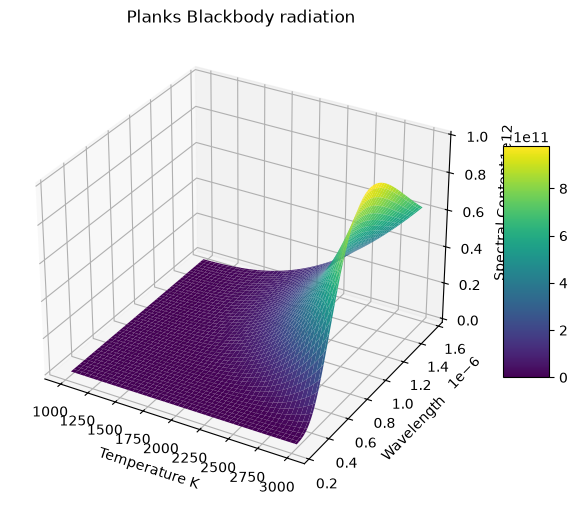

In [104]:
# Plot the resulting curve
# 1. Generate 3D grid data
x = np.linspace(1000, 3000, 100)         # Degrees kelvin
y = np.linspace(250, 1550, 100)          # wavelength in nm
X, Y = np.meshgrid(x, y*1.0e-9)          # convert wavelength to nm before mesh.
Z = BlackBody(Y,X)

# 2. Initialize the figure and 3D axes
fig = plt.figure(figsize=(8, 6))
ax = plt.axes(projection='3d')

# 3. Plot the surface with a colormap
# 'cmap' sets the color gradient, 'edgecolor' removes the wireframe lines for a smoother look
surf = ax.plot_surface(X, Y, Z, cmap='viridis', edgecolor='none')

# 4. Add a colorbar and labels
fig.colorbar(surf, ax=ax, shrink=0.5, aspect=5)  # Visual legend for colors
ax.set_title('Planks Blackbody radiation')
ax.set_xlabel('Temperature K')
ax.set_ylabel('Wavelength')
ax.set_zlabel('Spectral Content')

plt.show()

In [34]:
# peak
print('Peak radiance at 3000K: ', Wein(3000))

Peak radiance at 3000K:  9.659239850617242e-07


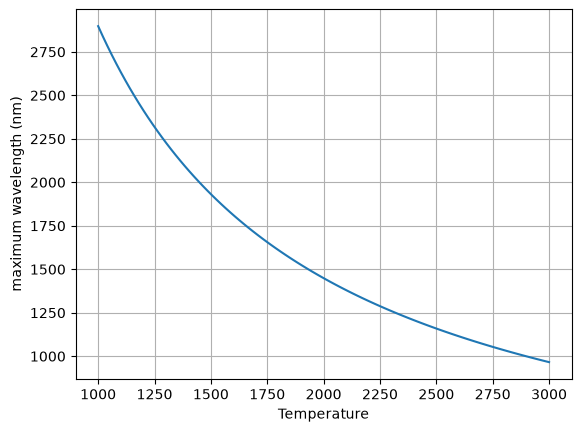

In [35]:
plt.plot(x,Wein(x)*1.0e9)
plt.xlabel('Temperature')
plt.ylabel('maximum wavelength (nm)')
plt.grid()

We see that the maximum wavelength diminishes significantly as the temperature goes lower. We also need the number of photons at that wavelength. To convert to photon nunber we have $N = {\lambda\over{hc}}B_\lambda$ \br

lets now look at the same plot not in terms of irradiance but rather photon number. 

Text(0.5, 0, 'Number photons')

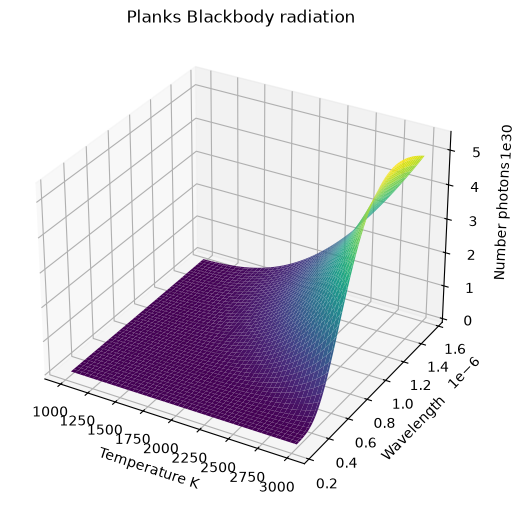

In [105]:
NZ = Z * Y/(const.h * const.c)
# 2. Initialize the figure and 3D axes
fig = plt.figure(figsize=(8, 6))
ax = plt.axes(projection='3d')
surf = ax.plot_surface(X, Y, NZ, cmap='viridis', edgecolor='none')
#fig.colorbar(surf, ax=ax, shrink=0.5, aspect=5)  # Visual legend for colors
ax.set_title('Planks Blackbody radiation')
ax.set_xlabel('Temperature K')
ax.set_ylabel('Wavelength')
ax.set_zlabel('Number photons')

Now let us model the filament temperature as a function of the current. 

Let us use the following model for a filmanet in a steady state condition. The filament temperature will be a number of factors. 

$I^2 R(T) = \epsilon (T) \sigma A (T^4 - {T_0}^4 ) + P_{conduction}(T) + P_{convection}(T)$

Here R is the filament resistance which changes with temperature which makes things a bit tricky. 

That is there are three components that will deal with the balance of the filament temperature 
<ol>
    <li> Radiation </li>
    <li> Conduction</li>
    <li> Convection</li>
</ol>

Convection is minimal since the bulb is evacuated.

Conduction could be an issue depending on the size of the filament leads and the material used. Kinda goes like $ K d/l$ where d is the diameter of the wire and l is the lenth from T1 to T2. 

Radiation is what we are looking for overall. 

Therefore we can simplify to Radiation component which is what we want to look at anyway. 

$I^2 R(T) \approx \epsilon \sigma (T^4 - {T_0}^4)$ 

$T_0$ is basically room temperature so roughly 300K

This is a little funny then but if we measure voltage with the current as an observable we can rewrite things. 

$R_{hot} = {V \over I}$

Substituting we have the balance equation:

$I V \approx \epsilon \sigma  A (T^4 - {T_0}^4)$ 

where $\epsilon$ is the emmisivitity of the filament and $\sigma$ is the Stefan-Boltzman constant.
A is the area of the filament and roughly $\pi d L$ where d is the filament diameter and L is the length in meters. 

final equation is:

$T \approx ({T_0}^4 + {{V I}\over{\epsilon \sigma A}})^{1\over4}$

In [39]:
def FilTemp(V,I,A):
    """
    @param V - voltage
    @param I - current
    @param A - area
    @return the filament emission temperature
    """
    T0 = 300   # assume 20C room temperature
    emissivity = 1.0  # full black body
    
    Val = np.power(T0,4) + V * I/(emissivity * const.sigma * A)
    return np.power(Val, 0.25)

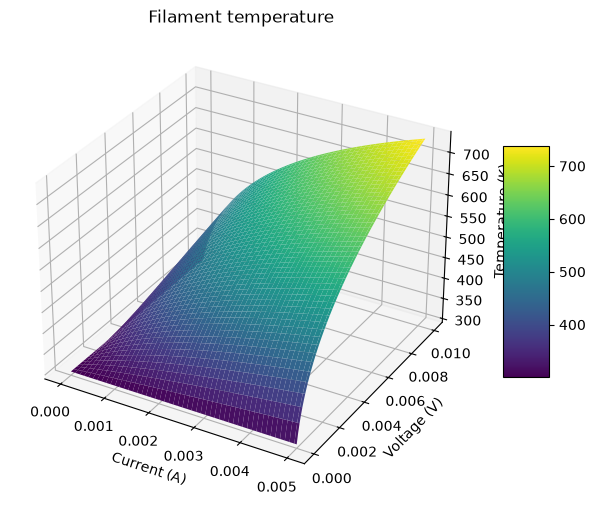

In [174]:
# Filament details
# Assume AWG 22 - 0.622mm
d = 0.622e-3 # meters
r = d/2
l = 1.0e-2   # meters (1cm)
AF = np.pi * np.power(r,2) * l
#
# Scan the IV ----------------------------------------------------------------
#
# Plot the resulting curve
# 1. Generate 3D grid data
x = np.linspace(1.0e-6, 5.0e-3, 100)     # current in A
y = np.linspace(1.0e-6, 1.0e-2, 100)     # voltage
X, Y = np.meshgrid(x, y)
FT = FilTemp(X,Y,AF)

# 2. Initialize the figure and 3D axes
fig = plt.figure(figsize=(8, 6))
ax = plt.axes(projection='3d')

# 3. Plot the surface with a colormap
# 'cmap' sets the color gradient, 'edgecolor' removes the wireframe lines for a smoother look
surf = ax.plot_surface(X, Y, FT, cmap='viridis', edgecolor='none')

# 4. Add a colorbar and labels
fig.colorbar(surf, ax=ax, shrink=0.5, aspect=5)  # Visual legend for colors
ax.set_title('Filament temperature')
ax.set_xlabel('Current (A)')
ax.set_ylabel('Voltage (V)')
ax.set_zlabel('Temperature (K)')

plt.show()

We see that the filament temperature really won't get any greater than the room temperature or background unless you cool the space. Thermal photons will end up being background in this case. Lets now calculate what N is at this temperture. 

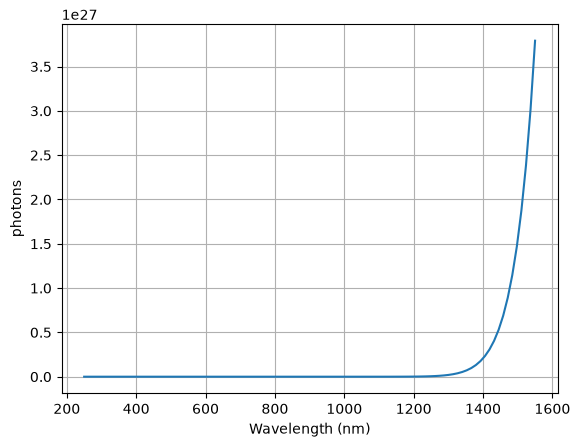

In [108]:
# Fix T and vary lambda
T = 300 # Kelven
Lambda = np.linspace(250, 1550, 100) # nm
BBR = BlackBody(Lambda*1.0e-9,T)
N = BBR * Lambda/(const.h * const.c)
plt.plot(Lambda, N)
plt.xlabel('Wavelength (nm)')
plt.ylabel('photons')
plt.grid()

What this really points out is that unless you have a narrowband filter you can't reach the low photon number necessary to say that you can difinitively say that a single photon is interacting with the apparatus at a time. Let's repeat the plot at around 700-900nm and see what we get. 

Lets choose a center wavelength of about 880 which is where many detectors have their peek efficiency with minimal dark current. Also lets consider a 20nm width filter at 880nm. These filters are not so expensive to buy.

The photon number will be: <br>
$ N_{band} = \int_{\lambda_1}^{\lambda_2} {N_{\lambda}} \,d{\lambda} $

For sufficently small increments of wavelength this can be approximated by a sum.

In [145]:
def Filter(T, Lambda_0, BW):
    """
    Do the integration for a filter centered at Lambda_0 and having a specific bandwidth. 
    T - temperature of source in K
    Lambda_0 - center wavelength of filter in m
    BW       - Bandwidth of filter in m
    """
    Lambda_1 = Lambda_0 - BW/2
    Lambda_2 = Lambda_0 + BW/2
    dLambda  = 1.0e-9   # Step size for sum. 
    Lambda = np.linspace(Lambda_1, Lambda_2, int(BW/dLambda)) # nm
    PN = PhotonNumber(Lambda, T)
    Bins = PN * dLambda
    Total_Photons = np.sum(Bins)
    return Total_Photons

In [132]:
T = 300             # Kelvin
Lambda_0 = 880e-9   # filter center wavelength (m)
BW       = 20.0e-9  # Bandwidth of filter (m)
TP       = Filter(T, Lambda_0, BW)
print('Total photon number for ', BW*1.0e9, ' nm filter centered at ', Lambda_0 * 1.0e9, ' is ', TP)

Total photon number for  20.0  nm filter centered at  880.0  is  45.41326792565348


This assumes a $4 \pi$ steradidan capture and 100% quantum efficency. Lets now add those in. 

In [151]:
def ExperimentalApparatus(N, theta, phi):
    """
    Correct for detector efficency and angle of usage. EG we don't see the full 4pi emitted. 
    @param N - number of photons emitted in 4pi steradians. 
    @param theta - polar angle, radians
    @param phi   - azmuthial angle, radians
    R - factors out since we want solid angle
    """
    QE_d = 0.1          # quantum efficency of detector
    QE_f = 0.1          # quantum efficency of filter
    Omega = np.sin(theta) * phi
    return (N*QE_d * QE_f * Omega)

In [152]:
d_theta = 10.0 * np.pi/180.0
d_phi   = 1.0  * np.pi/180.0
print('photons per second detected: ', ExperimentalApparatus(Total_Photons, d_theta, d_phi))

photons per second detected:  0.0013763546432576578


This is very low. Now we can play with the filament temperature. We need to come up by at least 5 orders of magnitude. This is also going to obey a Poission distribution in terms of photns per second. 

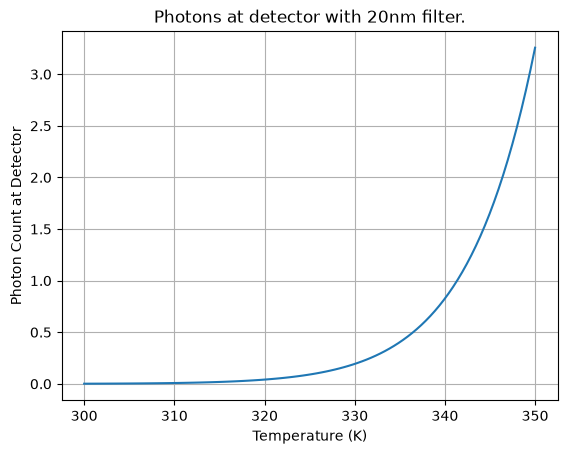

In [160]:
Lambda_0 = 880.0e-9   # center wavelength
BW       = 20.0e-9    # Bandwidth
T        = np.linspace(300, 350, 100) # K
# Filter only works with one temperature bin at a time. Make a loop. 
NP_raw   = np.zeros(len(T))
for Index in range(len(T)):
    NP_raw[Index]   = Filter(T[Index], Lambda_0, BW)
#
#
#
d_theta = 10.0 * np.pi/180.0
d_phi   = 1.0  * np.pi/180.0
NP_Filter = ExperimentalApparatus(NP_raw, d_theta, d_phi)
# Plot result
plt.plot(T, NP_Filter)
plt.title('Photons at detector with 20nm filter.')
plt.xlabel('Temperature (K)')
plt.ylabel('Photon Count at Detector')
plt.grid()

Depending on the readout speed of the detector this might be doable. What would be the voltage current then?  To achieve 350K at the filament? From the plot above it looks like a milliVolt and milliAmp. This assumes perfect emmisivity at the filament. Lets add a neutral Density filter in with a quantum effiency of 0.1 and see what it looks like. Lets choose 10 stops with an optical density of 3. 

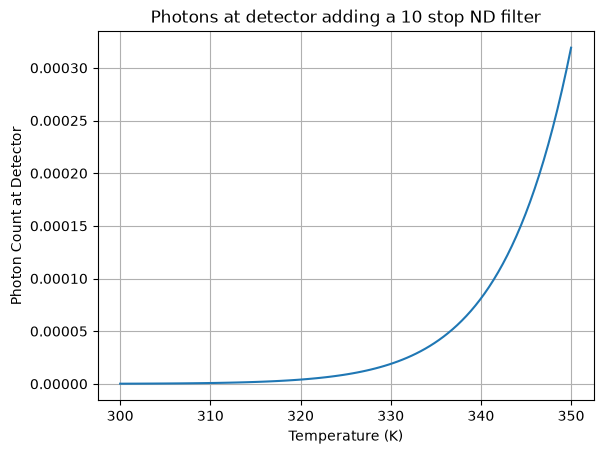

In [161]:
ND_Factor = 9.8e-4
ND_Eff    = 0.1
ND_Photons = NP_Filter * ND_Factor * ND_Eff
# Plot result
plt.plot(T, ND_Photons)
plt.title('Photons at detector adding a 10 stop ND filter')
plt.xlabel('Temperature (K)')
plt.ylabel('Photon Count at Detector')
plt.grid()

We can increase the temperature where the voltage and current will have a bit more tolerance. 

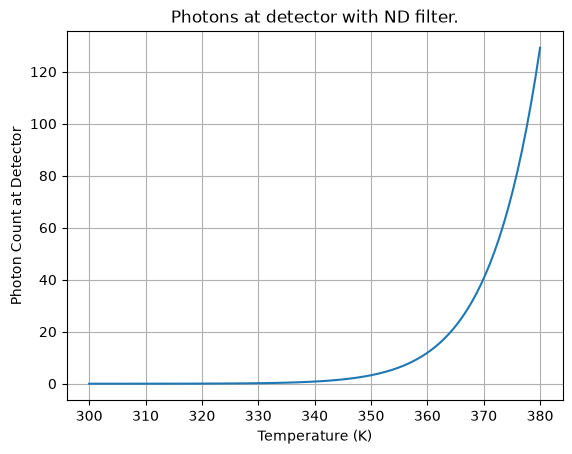

In [164]:
Lambda_0 = 880.0e-9   # center wavelength
BW       = 20.0e-9    # Bandwidth
T        = np.linspace(300, 380, 100) # K
# Filter only works with one temperature bin at a time. Make a loop. 
NP_raw   = np.zeros(len(T))
for Index in range(len(T)):
    NP_raw[Index]   = Filter(T[Index], Lambda_0, BW)
#
#
#
d_theta = 10.0 * np.pi/180.0
d_phi   = 1.0  * np.pi/180.0
NP_Filter = ExperimentalApparatus(NP_raw, d_theta, d_phi)
# Plot result
ND_Factor = 9.8e-4
ND_Eff    = 0.1
ND_Photons = NP_Filter * ND_Factor * ND_Eff
plt.plot(T, NP_Filter)
plt.title('Photons at detector with ND filter.')
plt.xlabel('Temperature (K)')
plt.ylabel('Photon Count at Detector')
plt.grid()

This is still a low voltage/current duo to get where we want to be. Let's take the idea of putting a pinhole at a distance from the source with a neutral density filter. This will reduce the angle substantially. 

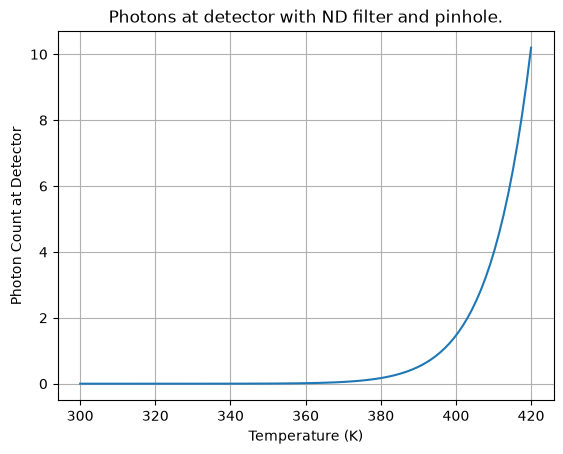

In [171]:
Lambda_0 = 880.0e-9   # center wavelength
BW       = 20.0e-9    # Bandwidth
T        = np.linspace(300, 420, 100) # K
# Filter only works with one temperature bin at a time. Make a loop. 
NP_raw   = np.zeros(len(T))
for Index in range(len(T)):
    NP_raw[Index]   = Filter(T[Index], Lambda_0, BW)
#
#
L = 0.05       # Pinhole 5cm from source
d = 0.0001     # pinhole diameter
d_theta = d/L
d_phi   = d_theta
#
NP_Filter = ExperimentalApparatus(NP_raw, d_theta, d_phi)
ND_Factor = 9.8e-4
ND_Eff    = 0.1
ND_Photons = NP_Filter * ND_Factor * ND_Eff
plt.plot(T, NP_Filter)
plt.title('Photons at detector with ND filter and pinhole.')
plt.xlabel('Temperature (K)')
plt.ylabel('Photon Count at Detector')
plt.grid()

What concerns me and why I'm trying hard to get into a regime where the voltage and current are a bit larger is that a low grade supply won't be able to hold the values well enough to keep the photon number low. We really want to get into the regime where the filament temperature is higher. Lets move onto the concept of using a photo-diode and potentially pulse modulating it to regulate the intensity. Other than adding in additional ND filters we won't get into a real controllable space. We can also assume 3000K and provide a BP filter and several ND filters. 